# AOL Deep Learning — Normalisasi Query Informal untuk RAG FAQ

In [2]:
!pip -q install datasets sentence-transformers sacrebleu sentencepiece huggingface_hub

import os, re, time, gc, math, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn.functional as F
import sentencepiece as spm
import sacrebleu
from datasets import load_dataset
from huggingface_hub import hf_hub_download
from transformers import MBartForConditionalGeneration, get_linear_schedule_with_warmup

SEED = 42
DEV = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEV == "cuda"
MODEL_ID = "indobenchmark/indobart-v2"
N_TEST = 150        # jumlah query uji (hanya yang berbentuk pertanyaan)
MAX_LEN = 64        # panjang maksimum token
BS = 16             # batch size
MAX_TRAIN = None    # isi mis. 800 jika harus berjalan di CPU

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

set_seed()
print("Device:", DEV)
if DEV == "cpu":
    print("PERINGATAN: CPU sangat lambat. Pakai runtime GPU, atau set MAX_TRAIN=800 dan jalankan Baseline saja.")

Device: cuda


## 1. Dataset: muat, bersihkan, dan bagi
Pembersihan: huruf kecil (tokenizer IndoBART memang meng-lowercase), placeholder `xxxnumberxxx` → `@number` agar pendek dan mudah disalin model, emoji/simbol aneh dibuang, duplikat dihapus. Pembersihan yang sama dipakai untuk sisi informal dan formal.

In [3]:
ds = load_dataset("haryoaw/stif-indonesia")
raw = pd.concat([ds[k].to_pandas() for k in ds.keys()], ignore_index=True) if hasattr(ds, "keys") else ds.to_pandas()
assert {"informal", "formal"} <= set(raw.columns), f"Kolom tidak sesuai: {list(raw.columns)}"
print("Baris mentah:", len(raw))

def clean(s):
    s = str(s).lower()
    s = re.sub(r"xxx(\w+?)xxx", r"@\1", s)
    s = re.sub(r"[^a-z0-9\s@.,?!\x27\x22()/:;%+*&=_#-]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

df = raw[["informal", "formal"]].copy()
df["informal"] = df["informal"].map(clean)
df["formal"] = df["formal"].map(clean)
df = df[(df.informal.str.len() > 0) & (df.formal.str.len() > 0)].drop_duplicates().reset_index(drop=True)

# Penentuan "pertanyaan": tanda tanya atau kata tanya utuh (pakai batas kata, bukan substring)
Q_WORDS = r"\b(apa|apakah|bagaimana|gimana|gmn|gmna|kenapa|knp|kapan|kpn|dimana|dmn|mana|berapa|brp|siapa|caranya|cara)\b"
df["is_q"] = [("?" in a) or ("?" in b) or bool(re.search(Q_WORDS, a)) for a, b in zip(df.informal, df.formal)]

# Split: test = pertanyaan acak; train/val = sisanya (tanpa duplikat dengan test)
rng = np.random.RandomState(SEED)
elig = df.index[df.is_q].to_numpy()
test_idx = rng.choice(elig, size=min(N_TEST, len(elig)), replace=False)
test_df = df.loc[test_idx].rename_axis("df_idx").reset_index()
test_df.insert(0, "test_id", range(len(test_df)))
rest = df.drop(index=test_idx)
rest = rest[~rest.informal.isin(set(test_df.informal)) & ~rest.formal.isin(set(test_df.formal))]
perm = rng.permutation(len(rest))
n_val = int(0.1 * len(rest))
val_df = rest.iloc[perm[:n_val]].reset_index(drop=True)
train_df = rest.iloc[perm[n_val:]].reset_index(drop=True)
if MAX_TRAIN: train_df = train_df.iloc[:MAX_TRAIN].reset_index(drop=True)

def profile(d, name):
    return {"split": name, "pairs": len(d), "question_%": round(100 * d.is_q.mean(), 1),
            "avg_words_informal": round(d.informal.str.split().str.len().mean(), 1),
            "avg_words_formal": round(d.formal.str.split().str.len().mean(), 1),
            "with_placeholder_%": round(100 * d.informal.str.contains("@").mean(), 1),
            "informal==formal_%": round(100 * (d.informal == d.formal).mean(), 1)}

print(pd.DataFrame([profile(train_df, "train"), profile(val_df, "val"), profile(test_df, "test")]).to_string(index=False))
print("\nPeriksa manual 8 contoh query uji (apakah benar pertanyaan?):")
print(test_df.sample(min(8, len(test_df)), random_state=1)[["informal", "formal"]].to_string(index=False))

# Ekspor query uji untuk diberi label FAQ gold secara manual (lihat bagian retrieval)
test_df[["test_id", "informal", "formal"]].to_csv("test_queries_for_labeling.csv", index=False)

README.md:   0%|          | 0.00/2.07k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/336k [00:00<?, ?B/s]

dev.csv:   0%|          | 0.00/36.2k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/65.3k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1922 [00:00<?, ? examples/s]

Generating dev split:   0%|          | 0/214 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/363 [00:00<?, ? examples/s]

Baris mentah: 2499
split  pairs  question_%  avg_words_informal  avg_words_formal  with_placeholder_%  informal==formal_%
train   2114        47.1                14.6              15.7                35.4                 1.3
  val    234        48.3                14.8              15.9                36.8                 1.7
 test    150       100.0                16.3              16.9                34.7                 2.7

Periksa manual 8 contoh query uji (apakah benar pertanyaan?):
                                                                                                                           informal                                                                                                                                 formal
                                             saya kirim uang , kenapa tidak masuk ? padahal status berhasil dan saldo sya terpotong                                             saya kirim uang , mengapa tidak masuk ? padahal status berhasil

## 2. Leksikon slang (untuk baseline berbasis aturan dan augmentasi E3)
Kamus kecil formal → varian informal. Dipakai (a) terbalik sebagai **normalizer aturan** (referensi tanpa pelatihan) dan (b) maju sebagai **augmentasi** pada kalimat formal data latih (hanya E3). Catatan: karena memakai leksikon yang sama, normalizer aturan bukan pembanding yang sepenuhnya independen terhadap E3.

In [4]:
SLANG = {
    "tidak": ["gak", "ga", "nggak", "gk", "tdk"], "sudah": ["udah", "udh", "sdh", "dah"], "belum": ["blm", "belom"],
    "bagaimana": ["gimana", "gmn"], "kenapa": ["knp", "napa"], "bisa": ["bs"], "saya": ["sy", "aku"],
    "tetapi": ["tp"], "karena": ["krn"], "dengan": ["dgn"], "yang": ["yg"], "untuk": ["utk"],
    "kalau": ["kalo", "klo"], "sangat": ["bgt", "banget"], "terima kasih": ["makasih", "thx"], "admin": ["min"],
    "sedang": ["lg"], "dapat": ["dpt"], "hanya": ["cuma", "cm"], "juga": ["jg"], "tolong": ["tlg"],
    "dari": ["dr"], "pada": ["pd"],
}
INV = {v: k for k, vs in SLANG.items() for v in vs}
_inv_re = re.compile(r"\b(" + "|".join(map(re.escape, sorted(INV, key=len, reverse=True))) + r")\b")
AUG_RNG = random.Random(SEED)

def rule_normalize(text):
    return _inv_re.sub(lambda m: INV[m.group(1)], text)

def informalize(text, p=0.7, rng=None):
    rng = rng or AUG_RNG
    for formal, variants in SLANG.items():
        pat = rf"\b{re.escape(formal)}\b"
        if re.search(pat, text) and rng.random() < p:
            text = re.sub(pat, rng.choice(variants), text)
    return text

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    hit = np.mean([bool(_inv_re.search(s)) for s in d.informal])
    print(f"{name}: {100 * hit:.1f}% query informal mengandung slang dari leksikon")

train: 62.3% query informal mengandung slang dari leksikon
val: 62.4% query informal mengandung slang dari leksikon
test: 67.3% query informal mengandung slang dari leksikon


## 3. Tokenizer IndoBART dan model dasar
Format mengikuti `IndoNLGTokenizer`: encoder `<s> X </s> [indonesian]`, decoder input `[indonesian] <s> Y </s>`, label `<s> Y </s> [indonesian]`. Saat generasi, decoder dimulai dari token `[indonesian]`. Embedding token **selalu dibekukan** di semua skenario (sama seperti versi awal).

In [5]:
def _pad(seqs, value):
    m = max(len(s) for s in seqs)
    return torch.tensor([s + [value] * (m - len(s)) for s in seqs])

class IndoBartTok:
    def __init__(self, path):
        self.sp = spm.SentencePieceProcessor(); self.sp.Load(path)
        self.bos, self.eos = self.sp.PieceToId("<s>"), self.sp.PieceToId("</s>")
        self.pad = self.sp.PieceToId("<pad>")
        self.lang = 40002                      # id token [indonesian] pada IndoBART
        self.n_sp = self.sp.GetPieceSize()
        if self.n_sp != 40000:
            print(f"PERINGATAN: ukuran vocab sentencepiece {self.n_sp} (diharapkan 40000). Periksa model card.")
    def ids(self, text):
        return self.sp.encode(text.lower(), out_type=int)
    def pack(self, src, tgt=None):
        L = MAX_LEN - 3
        S = [[self.bos] + self.ids(s)[:L] + [self.eos, self.lang] for s in src]
        b = {"input_ids": _pad(S, self.pad)}
        b["attention_mask"] = (b["input_ids"] != self.pad).long()
        if tgt is not None:
            T = [self.ids(t)[:L] for t in tgt]
            b["decoder_input_ids"] = _pad([[self.lang, self.bos] + t + [self.eos] for t in T], self.pad)
            b["labels"] = _pad([[self.bos] + t + [self.eos, self.lang] for t in T], -100)
        return b
    def decode(self, ids):
        ids = list(ids)
        if ids and ids[0] == self.lang: ids = ids[1:]
        out = []
        for i in ids:
            if i == self.eos: break
            if i in (self.bos, self.pad) or i >= self.n_sp: continue
            out.append(int(i))
        return self.sp.decode(out).strip()

TOK = IndoBartTok(hf_hub_download(MODEL_ID, "sentencepiece.bpe.model"))

# Uji sanity tokenizer: round-trip harus identik
s = "min pembelian token pln apa ada kendala ?"
assert TOK.decode([TOK.lang, TOK.bos] + TOK.ids(s) + [TOK.eos]) == s, "Round-trip tokenizer gagal"
too_long = np.mean([len(TOK.ids(x)) > MAX_LEN - 3 for x in train_df.informal])
print(f"Tokenizer OK. Query latih terpotong oleh MAX_LEN: {100 * too_long:.1f}%")

def load_base():
    m = MBartForConditionalGeneration.from_pretrained(MODEL_ID)
    if m.get_input_embeddings().num_embeddings < 40004:
        m.resize_token_embeddings(40004)
    return m.to(DEV)

@torch.no_grad()
def normalize(model, texts, bs=32, max_new=MAX_LEN):
    model.eval(); outs = []
    for i in range(0, len(texts), bs):
        b = TOK.pack(texts[i:i + bs])
        gen = model.generate(input_ids=b["input_ids"].to(DEV), attention_mask=b["attention_mask"].to(DEV),
                             decoder_start_token_id=TOK.lang, eos_token_id=TOK.eos, pad_token_id=TOK.pad,
                             max_new_tokens=max_new, num_beams=1, do_sample=False)
        outs += [TOK.decode(g) for g in gen.tolist()]
    return outs

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B /  932kB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

Tokenizer OK. Query latih terpotong oleh MAX_LEN: 0.3%


## 4. Metrik
Normalizer: **chrF** (utama), BLEU, exact match, dan persentase placeholder (`@number`, `@user`) yang terjaga. Dua referensi tanpa pelatihan: **R0_raw** (query dibiarkan, setara baseline salin-input) dan **R_rule** (normalizer aturan). Selisih antar kondisi dilaporkan dengan CI 95% dari bootstrap berpasangan.

In [6]:
def per_query_chrf(hyps, refs):
    return np.array([sacrebleu.sentence_chrf(h, [r]).score for h, r in zip(hyps, refs)])

def ph_ok(h, r):
    return sorted(re.findall(r"@\w+", h)) == sorted(re.findall(r"@\w+", r))

def eval_norm(hyps, refs):
    return {"chrF": round(sacrebleu.corpus_chrf(hyps, [refs]).score, 2),
            "BLEU": round(sacrebleu.corpus_bleu(hyps, [refs]).score, 2),
            "exact_%": round(100 * np.mean([h.strip() == r.strip() for h, r in zip(hyps, refs)]), 2),
            "placeholder_ok_%": round(100 * np.mean([ph_ok(h, r) for h, r in zip(hyps, refs)]), 1)}

def paired_bootstrap(a, b, n=2000, seed=SEED):
    a, b = np.asarray(a, float), np.asarray(b, float)
    idx = np.random.RandomState(seed).randint(0, len(a), size=(n, len(a)))
    d = (a[idx] - b[idx]).mean(1)
    return round(float((a - b).mean()), 4), (round(float(np.percentile(d, 2.5)), 4), round(float(np.percentile(d, 97.5)), 4))

REF = test_df.formal.tolist()
INF = test_df.informal.tolist()
PREDS = {"R0_raw": INF, "R_rule": [rule_normalize(x) for x in INF]}
print("R0_raw :", eval_norm(PREDS["R0_raw"], REF))
print("R_rule :", eval_norm(PREDS["R_rule"], REF))

R0_raw : {'chrF': 65.45, 'BLEU': 36.68, 'exact_%': np.float64(2.67), 'placeholder_ok_%': np.float64(97.3)}
R_rule : {'chrF': 70.9, 'BLEU': 41.99, 'exact_%': np.float64(3.33), 'placeholder_ok_%': np.float64(97.3)}


## 5. Pelatihan normalizer (Baseline + skenario eksperimen)
Konfigurasi tetap di semua skenario: loss cross-entropy dengan label smoothing 0,1, AdamW (weight decay 0,01), warmup 6% lalu penurunan linear, gradient clipping 1,0, batch 16, seed sama, split sama, dan pemilihan checkpoint terbaik berdasarkan val loss dengan early stopping (patience 2). Loss latih dan val yang dilaporkan adalah cross-entropy biasa (tanpa smoothing) supaya kedua kurva sebanding.

| ID | Variabel yang diubah (satu per skenario) |
|---|---|
| Baseline | Encoder dibekukan, hanya decoder dilatih; 3 epoch; lr 5e-5; tanpa augmentasi |
| E1 | **Layer yang dilatih:** encoder ikut dilatih |
| E2 | **Jumlah epoch:** 3 → 10 (dengan early stopping) |
| E3 | **Augmentasi:** tambah pasangan sintetis dari kalimat formal data latih |

In [7]:
def batch_to_dev(b):
    return {k: v.to(DEV) for k, v in b.items()}

@torch.no_grad()
def eval_loss(model, d):
    model.eval(); tot, n = 0.0, 0
    for i in range(0, len(d), 32):
        b = batch_to_dev(TOK.pack(d.informal[i:i + 32].tolist(), d.formal[i:i + 32].tolist()))
        logits = model(input_ids=b["input_ids"], attention_mask=b["attention_mask"], decoder_input_ids=b["decoder_input_ids"]).logits.float()
        tot += F.cross_entropy(logits.view(-1, logits.size(-1)), b["labels"].view(-1), ignore_index=-100, reduction="sum").item()
        n += (b["labels"] != -100).sum().item()
    return tot / n

def run_training(freeze_encoder=True, epochs=3, lr=5e-5, augment=False, patience=2):
    set_seed()
    model = load_base()
    for p in model.model.shared.parameters(): p.requires_grad = False          # embedding token selalu beku
    if freeze_encoder:
        for p in model.model.encoder.parameters(): p.requires_grad = False
    tr_src, tr_tgt = train_df.informal.tolist(), train_df.formal.tolist()
    n_aug = 0
    if augment:
        pairs = [(informalize(f), f) for f in train_df.formal]
        pairs = [(a, f) for a, f in pairs if a != f]
        n_aug = len(pairs); tr_src += [a for a, _ in pairs]; tr_tgt += [f for _, f in pairs]
    named = dict(model.named_parameters())
    train_names = [n for n, p in named.items() if p.requires_grad]
    params = [named[n] for n in train_names]
    total = sum(p.numel() for p in model.parameters()) / 1e6
    trainable = sum(p.numel() for p in params) / 1e6
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.01)
    steps = epochs * math.ceil(len(tr_src) / BS)
    sch = get_linear_schedule_with_warmup(opt, int(0.06 * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    hist = {"epoch": [], "train_loss": [], "val_loss": []}
    best, best_ep, bad, best_state = 1e9, 0, 0, None
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train(); order = np.random.RandomState(SEED + ep).permutation(len(tr_src)); tl, tn = 0.0, 0
        for i in range(0, len(order), BS):
            ids = order[i:i + BS]
            b = batch_to_dev(TOK.pack([tr_src[j] for j in ids], [tr_tgt[j] for j in ids]))
            with torch.autocast(device_type="cuda" if USE_AMP else "cpu", dtype=torch.float16, enabled=USE_AMP):
                logits = model(input_ids=b["input_ids"], attention_mask=b["attention_mask"], decoder_input_ids=b["decoder_input_ids"]).logits
            logits = logits.float(); V = logits.size(-1)
            loss = F.cross_entropy(logits.view(-1, V), b["labels"].view(-1), ignore_index=-100, label_smoothing=0.1)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update(); sch.step()
            with torch.no_grad():
                tl += F.cross_entropy(logits.detach().view(-1, V), b["labels"].view(-1), ignore_index=-100, reduction="sum").item()
                tn += (b["labels"] != -100).sum().item()
        vl = eval_loss(model, val_df)
        hist["epoch"].append(ep); hist["train_loss"].append(tl / tn); hist["val_loss"].append(vl)
        print(f"  epoch {ep}/{epochs}  train {tl / tn:.4f}  val {vl:.4f}")
        if vl < best - 1e-4:
            best, best_ep, bad = vl, ep, 0
            best_state = {n: named[n].detach().cpu().clone() for n in train_names}
        else:
            bad += 1
            if bad >= patience: print("  early stopping"); break
    with torch.no_grad():
        for n, v in best_state.items(): named[n].copy_(v.to(DEV))
    return dict(model=model, hist=hist, best_val=best, best_epoch=best_ep, train_min=(time.time() - t0) / 60,
                params_M=total, trainable_M=trainable, n_aug=n_aug, n_train=len(tr_src))

def diagnose(h):
    tr, va = h["train_loss"], h["val_loss"]; be = int(np.argmin(va)) + 1
    if len(va) < 2: return "Terlalu sedikit epoch untuk diagnosis."
    if va[-1] > min(va) * 1.02 and tr[-1] < tr[-2]:
        return f"Indikasi overfitting: val loss terendah di epoch {be}, lalu naik sementara train loss masih turun."
    if va[-1] < va[-2] - 0.01 and tr[-1] < tr[-2] - 0.01:
        return "Indikasi underfitting: kedua loss masih turun di epoch terakhir (tambah epoch/kapasitas)."
    return f"Relatif stabil (val loss terbaik di epoch {be}, selisih val-train akhir {va[-1] - tr[-1]:.3f})."

In [8]:
EXPERIMENTS = {
    "Baseline": dict(freeze_encoder=True,  epochs=3,  lr=5e-5, augment=False),
    "E1":       dict(freeze_encoder=False, epochs=3,  lr=5e-5, augment=False),   # ubah: layer yang dilatih
    "E2":       dict(freeze_encoder=True,  epochs=10, lr=5e-5, augment=False),   # ubah: jumlah epoch
    "E3":       dict(freeze_encoder=True,  epochs=3,  lr=5e-5, augment=True),    # ubah: augmentasi
}
RUN = ["Baseline", "E1", "E2", "E3"]

HIST, INFO = {}, {}
for name in RUN:
    print(f"\n=== {name}: {EXPERIMENTS[name]} ===")
    r = run_training(**EXPERIMENTS[name])
    t0 = time.time(); PREDS[name] = normalize(r["model"], INF)
    lat = (time.time() - t0) * 1000 / len(INF)
    HIST[name] = r["hist"]
    INFO[name] = {"val_loss_best": round(r["best_val"], 4), "best_epoch": r["best_epoch"], "train_min": round(r["train_min"], 2),
                  "params_M": round(r["params_M"], 1), "trainable_M": round(r["trainable_M"], 1),
                  "n_train": r["n_train"], "latency_ms/q": round(lat, 1)}
    print("  diagnosis:", diagnose(r["hist"]))
    print("  norm test:", eval_norm(PREDS[name], REF))
    del r; gc.collect(); torch.cuda.empty_cache()

print("\nContoh output (periksa awal kata tidak hilang):")
for i in range(4):
    print("- informal:", INF[i])
    for name in RUN: print(f"  {name:9s}:", PREDS[name][i])
    print("  target   :", REF[i])


=== Baseline: {'freeze_encoder': True, 'epochs': 3, 'lr': 5e-05, 'augment': False} ===


config.json:   0%|          | 0.00/1.71k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  526MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  526MB            

model.safetensors: downloading bytes:           |  0.00B            

... (4 outputs left out)

Loading weights:   0%|          | 0/267 [00:00<?, ?it/s]

  epoch 1/10  train 1.5479  val 0.9987
  epoch 2/10  train 0.9737  val 0.9125
  epoch 3/10  train 0.7809  val 0.8900
  epoch 4/10  train 0.6441  val 0.8771
  epoch 5/10  train 0.5385  val 0.8745
  epoch 6/10  train 0.4639  val 0.8983
  epoch 7/10  train 0.4108  val 0.9128
  early stopping
  diagnosis: Indikasi overfitting: val loss terendah di epoch 5, lalu naik sementara train loss masih turun.
  norm test: {'chrF': 77.67, 'BLEU': 55.68, 'exact_%': np.float64(8.0), 'placeholder_ok_%': np.float64(90.7)}

=== E3: {'freeze_encoder': True, 'epochs': 3, 'lr': 5e-05, 'augment': True} ===


Loading weights:   0%|          | 0/267 [00:00<?, ?it/s]

  epoch 1/3  train 0.8779  val 1.0350
  epoch 2/3  train 0.5870  val 0.9534
  epoch 3/3  train 0.4890  val 0.9315
  diagnosis: Indikasi underfitting: kedua loss masih turun di epoch terakhir (tambah epoch/kapasitas).
  norm test: {'chrF': 76.95, 'BLEU': 53.08, 'exact_%': np.float64(6.67), 'placeholder_ok_%': np.float64(91.3)}

Contoh output (periksa awal kata tidak hilang):
- informal: ini min minta tolong di cek sudah sampe mana . masa sudah @number minggu blm sampe . tolong banget min di update smp mana
  Baseline : ini admin , minta tolong dicek sudah sampai mana . masa sudah @number minggu belum sampai . tolong banget admin di update smp mana .
  E1       : admin , minta tolong diperiksa sudah sampai mana . masa sudah @number minggu belum sampai . tolong banget admin di update sampai mana ?
  E2       : ini admin , minta tolong dicek sudah sampai mana . masa sudah @number minggu belum sampai . tolong banget admin di update smp mana .
  E3       : ini admin minta tolong dicek sudah 

## 6. Retrieval
Dua mode:
- **Mode FAQ nyata (disarankan, valid untuk laporan):** letakkan `faq.csv` (kolom `faq_id,question,answer`) dan `gold.csv` (kolom `test_id,faq_id`) di folder kerja. Beri label FAQ gold untuk query di `test_queries_for_labeling.csv`; query tanpa label dilewati.
- **Mode proxy (hanya untuk uji pipeline):** korpus = kalimat formal seluruh data, gold = kembaran formal tiap query. Ini **bukan** pencarian FAQ sungguhan, dan Oracle otomatis sempurna, jadi angkanya jangan dipakai sebagai kesimpulan.

In [14]:
from sentence_transformers import SentenceTransformer
enc = SentenceTransformer("intfloat/multilingual-e5-small", device=DEV)
def embed(texts, prefix):
    return enc.encode([prefix + t for t in texts], normalize_embeddings=True, batch_size=64, convert_to_numpy=True, show_progress_bar=False)

REAL = os.path.exists("faq.csv") and os.path.exists("gold.csv")
if REAL:
    faq = pd.read_csv("faq.csv"); gold = pd.read_csv("gold.csv")
    pos = {fid: i for i, fid in enumerate(faq.faq_id)}
    gold = gold[gold.test_id.isin(test_df.test_id) & gold.faq_id.isin(pos)]
    eval_rows = test_df.index[test_df.test_id.isin(gold.test_id)].to_numpy()
    g_map = dict(zip(gold.test_id, gold.faq_id))
    gold_idx = np.array([pos[g_map[test_df.test_id[i]]] for i in eval_rows])
    corpus = faq.question.map(clean).tolist()
    print(f"MODE: FAQ NYATA | {len(faq)} dokumen | {len(eval_rows)} query berlabel")
else:
    eval_rows = np.arange(len(test_df))
    gold_idx = test_df.df_idx.to_numpy()
    corpus = df.formal.tolist()
    print("MODE: PROXY (korpus = kalimat formal seluruh data). Hanya untuk uji pipeline, bukan hasil laporan.")
CORP = embed(corpus, "passage: ")

PREDS["Oracle_formal"] = REF
RANKS = {}
for name, qs in PREDS.items():
    q = embed([qs[i] for i in eval_rows], "query: ")
    sims = q @ CORP.T
    g = sims[np.arange(len(q)), gold_idx]
    RANKS[name] = (sims > g[:, None]).sum(1) + 1

def summarize(rank):
    return {"R@1": round(100 * np.mean(rank <= 1), 1), "R@3": round(100 * np.mean(rank <= 3), 1), "MRR": round(float(np.mean(1 / rank)), 3)}
print(pd.DataFrame({k: summarize(v) for k, v in RANKS.items()}).T.to_string())

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MODE: FAQ NYATA | 30 dokumen | 126 query berlabel
                R@1   R@3    MRR
R0_raw         52.4  69.8  0.639
R_rule         50.8  69.8  0.634
Baseline       54.0  67.5  0.649
E1             53.2  70.6  0.649
E2             54.0  68.3  0.654
E3             53.2  65.1  0.643
Oracle_formal  52.4  69.8  0.645


## 7. Tabel hasil, kurva loss, dan uji selisih
Keluaran untuk laporan: `results_table.csv` (tabel hasil, waktu training, jumlah parameter), `loss_curves.png` (kurva train/val), dan selisih berpasangan dengan CI 95%.

    condition  chrF  BLEU  exact_%  placeholder_ok_%  R@1  R@3   MRR  val_loss_best  best_epoch  train_min  params_M  trainable_M  n_train  latency_ms/q
       R0_raw 65.45 36.68     2.67              97.3 52.4 69.8 0.639            NaN         NaN        NaN       NaN          NaN      NaN           NaN
       R_rule 70.90 41.99     3.33              97.3 50.8 69.8 0.634            NaN         NaN        NaN       NaN          NaN      NaN           NaN
     Baseline 76.56 53.46     7.33              91.3 54.0 67.5 0.649         0.8984         3.0       1.02     131.5         57.5   2114.0          11.7
           E1 78.46 56.63     7.33              91.3 53.2 70.6 0.649         0.8384         3.0       0.87     131.5        100.8   2114.0          14.5
           E2 77.67 55.68     8.00              90.7 54.0 68.3 0.654         0.8745         5.0       1.32     131.5         57.5   2114.0          10.8
           E3 76.95 53.08     6.67              91.3 53.2 65.1 0.643         0.931

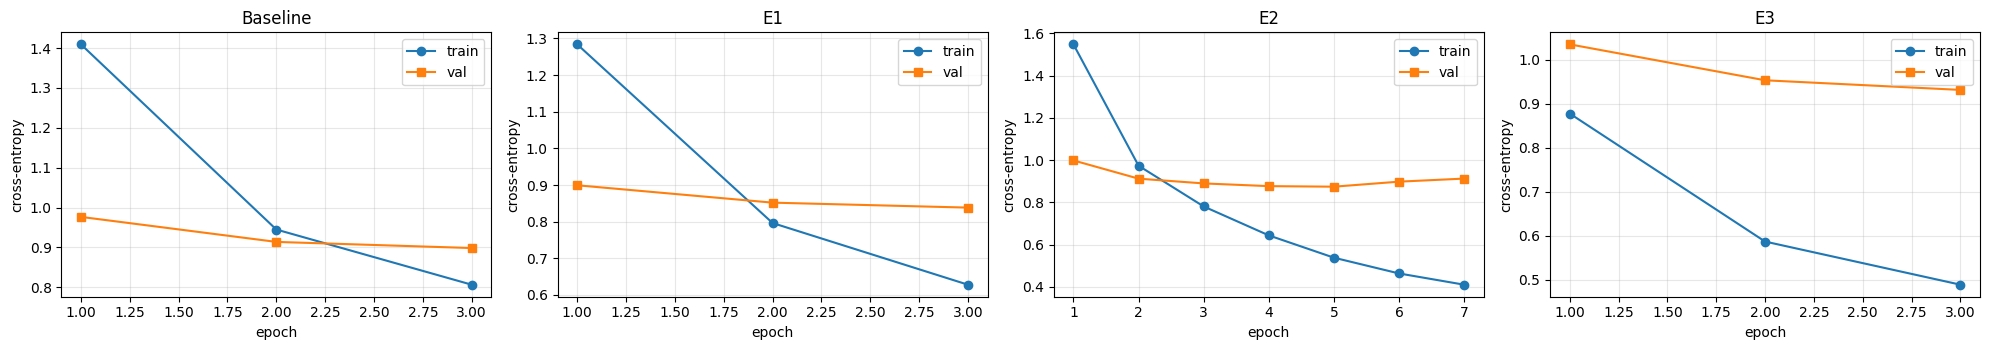

Baseline: Indikasi underfitting: kedua loss masih turun di epoch terakhir (tambah epoch/kapasitas).
E1: Indikasi underfitting: kedua loss masih turun di epoch terakhir (tambah epoch/kapasitas).
E2: Indikasi overfitting: val loss terendah di epoch 5, lalu naik sementara train loss masih turun.
E3: Indikasi underfitting: kedua loss masih turun di epoch terakhir (tambah epoch/kapasitas).

Selisih berpasangan (positif = kondisi pertama lebih baik):
Baseline - R0_raw  | chrF/query: 12.2397 CI95 (10.1924, 14.3175)
Baseline - R0_raw  | Recall@1  : 0.0159 CI95 (-0.0714, 0.1032)
E1 - R0_raw  | chrF/query: 13.8981 CI95 (11.8116, 15.9519)
E1 - R0_raw  | Recall@1  : 0.0079 CI95 (-0.0794, 0.0873)
E2 - R0_raw  | chrF/query: 13.0399 CI95 (11.1105, 14.9397)
E2 - R0_raw  | Recall@1  : 0.0159 CI95 (-0.0635, 0.0952)
E3 - R0_raw  | chrF/query: 12.3864 CI95 (10.4807, 14.3744)
E3 - R0_raw  | Recall@1  : 0.0079 CI95 (-0.0794, 0.0875)
E1 - Baseline | chrF/query: 1.6584 CI95 (0.6227, 2.6423)
E1 - Baseline | Re

In [15]:
rows = []
for name in PREDS:
    r = {"condition": name}
    if name != "Oracle_formal": r.update(eval_norm(PREDS[name], REF))
    r.update(summarize(RANKS[name])); r.update(INFO.get(name, {}))
    rows.append(r)
res = pd.DataFrame(rows); res.to_csv("results_table.csv", index=False)
print(res.to_string(index=False))

# Kurva loss
fig, axes = plt.subplots(1, len(RUN), figsize=(5 * len(RUN), 3.6), squeeze=False)
for ax, name in zip(axes[0], RUN):
    h = HIST[name]
    ax.plot(h["epoch"], h["train_loss"], marker="o", label="train"); ax.plot(h["epoch"], h["val_loss"], marker="s", label="val")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.set_ylabel("cross-entropy"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig("loss_curves.png", dpi=200); plt.show()
for name in RUN: print(f"{name}: {diagnose(HIST[name])}")

# Selisih berpasangan (CI 95% bootstrap)
CH = {n: per_query_chrf(p, REF) for n, p in PREDS.items() if n != "Oracle_formal"}
hit1 = {n: (r <= 1).astype(float) for n, r in RANKS.items()}
print("\nSelisih berpasangan (positif = kondisi pertama lebih baik):")
for n in RUN:
    d, ci = paired_bootstrap(CH[n], CH["R0_raw"]);  print(f"{n} - R0_raw  | chrF/query: {d} CI95 {ci}")
    d, ci = paired_bootstrap(hit1[n], hit1["R0_raw"]); print(f"{n} - R0_raw  | Recall@1  : {d} CI95 {ci}")
if "Baseline" in RUN:
    for n in [x for x in RUN if x != "Baseline"]:
        d, ci = paired_bootstrap(CH[n], CH["Baseline"]);  print(f"{n} - Baseline | chrF/query: {d} CI95 {ci}")
        d, ci = paired_bootstrap(hit1[n], hit1["Baseline"]); print(f"{n} - Baseline | Recall@1  : {d} CI95 {ci}")

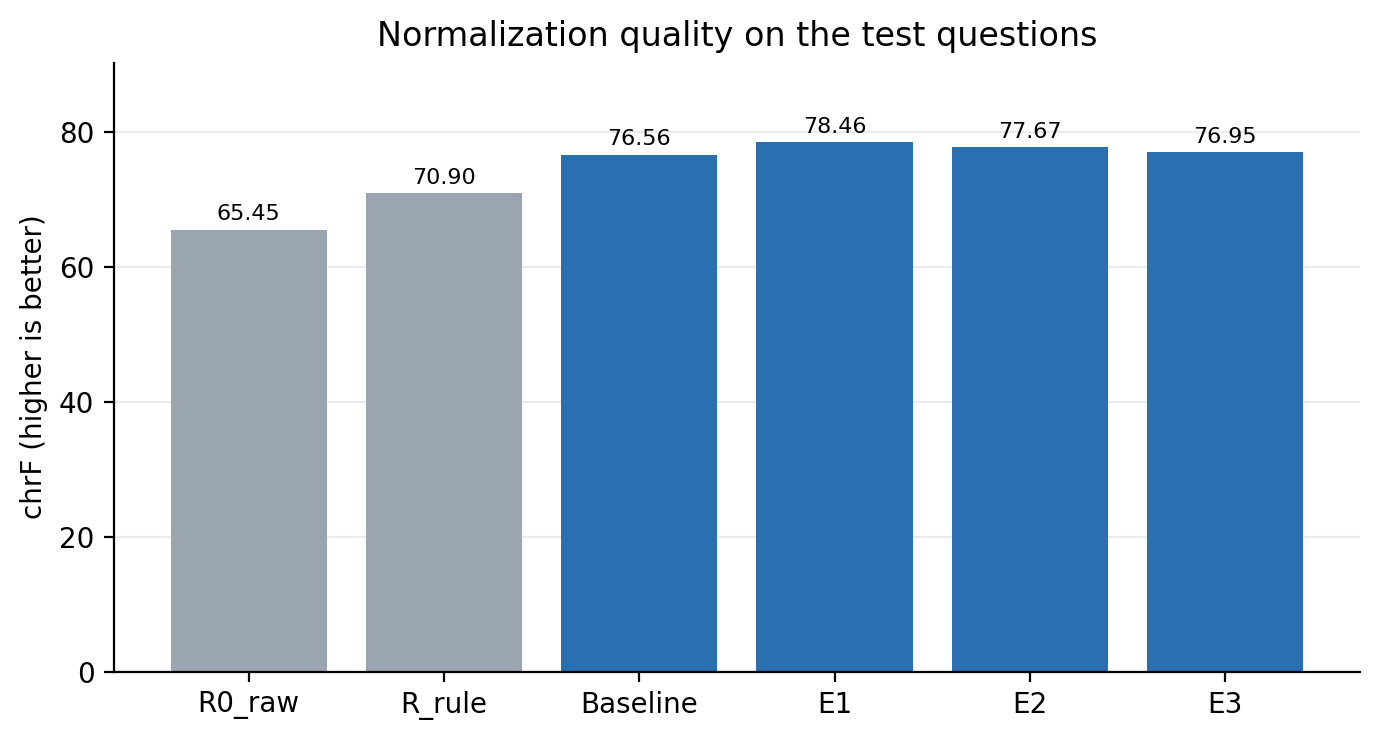

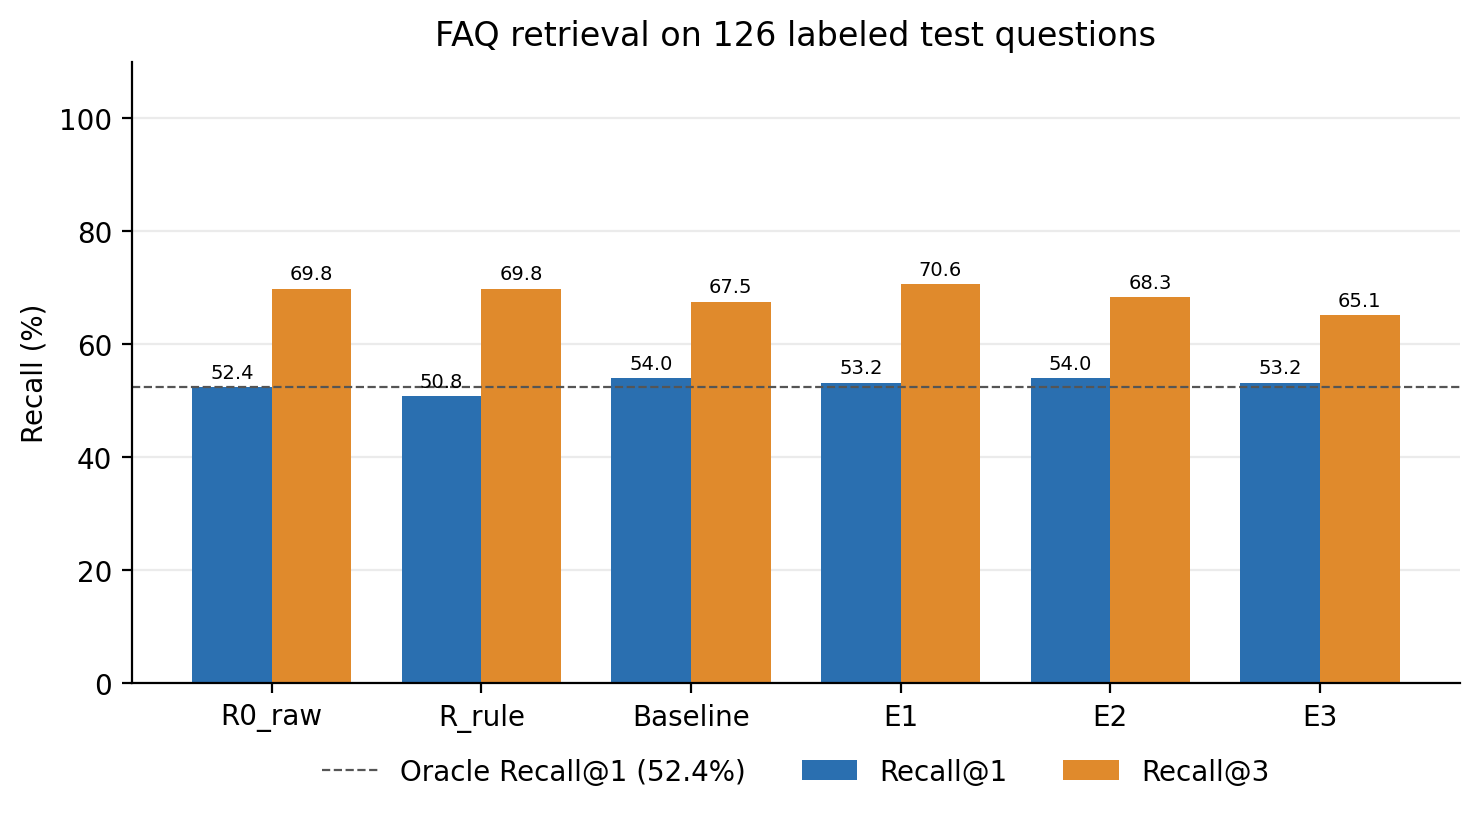

In [16]:
import numpy as np, matplotlib.pyplot as plt

ORDER = ["R0_raw", "R_rule", "Baseline", "E1", "E2", "E3"]
GREY, BLUE, ORANGE = "#9aa5b1", "#2a6fb0", "#e08a2c"
d = res.set_index("condition")
names = [c for c in ORDER if c in d.index]

def clean_axes(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=.25); ax.set_axisbelow(True)

# ---- Figure 1: kualitas normalisasi (chrF) ----
vals = d.loc[names, "chrF"].to_numpy()
fig, ax = plt.subplots(figsize=(7, 3.8), dpi=200)
bars = ax.bar(names, vals, color=[GREY if n in ("R0_raw", "R_rule") else BLUE for n in names])
ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8)
ax.set_ylim(0, vals.max() * 1.15); ax.set_ylabel("chrF (higher is better)")
ax.set_title("Normalization quality on the test questions"); clean_axes(ax)
fig.tight_layout(); fig.savefig("fig_chrf.png"); plt.show()

# ---- Figure 3: retrieval FAQ (hanya valid pada mode FAQ nyata) ----
if not REAL:
    print("Figure retrieval DILEWATI: faq.csv + gold.csv tidak ditemukan, notebook berjalan di mode proxy.\n"
          "Angka mode proxy (Oracle otomatis ~100%) bukan hasil FAQ sungguhan dan tidak boleh masuk laporan.\n"
          "Letakkan faq.csv dan gold.csv di folder kerja, jalankan ulang sel retrieval, lalu jalankan sel ini lagi.")
else:
    n_q = len(next(iter(RANKS.values())))
    x, w = np.arange(len(names)), 0.38
    fig, ax = plt.subplots(figsize=(7.5, 4.2), dpi=200)
    a = ax.bar(x - w / 2, d.loc[names, "R@1"], w, label="Recall@1", color=BLUE)
    c = ax.bar(x + w / 2, d.loc[names, "R@3"], w, label="Recall@3", color=ORANGE)
    ax.bar_label(a, fmt="%.1f", padding=2, fontsize=7); ax.bar_label(c, fmt="%.1f", padding=2, fontsize=7)
    if "Oracle_formal" in d.index:
        o = float(d.loc["Oracle_formal", "R@1"])
        ax.axhline(o, ls="--", lw=.8, color="#555", label=f"Oracle Recall@1 ({o:.1f}%)")
    ax.set_xticks(x); ax.set_xticklabels(names)
    ax.set_ylim(0, 110); ax.set_yticks(range(0, 101, 20)); ax.set_ylabel("Recall (%)")
    ax.set_title(f"FAQ retrieval on {n_q} labeled test questions"); clean_axes(ax)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
    fig.tight_layout(); fig.savefig("fig_retrieval.png"); plt.show()

## 8. Generasi jawaban dengan Qwen2.5-1.5B
Hanya berjalan jika mode FAQ nyata dan GPU tersedia. Sel ini tidak memberi skor otomatis yang menyesatkan: ia menyimpan jawaban ke `gen_outputs.csv` untuk dinilai manual (kolom `correct` dan `faithful`, 0/1) dengan rubrik yang sama untuk semua kondisi, dan menghitung tumpang tindih kata dengan konteks sebagai indikator kasar saja.

In [17]:
RUN_GEN = REAL and DEV == "cuda"
N_GEN = 30
if not RUN_GEN:
    print("Dilewati: butuh faq.csv + gold.csv dan GPU.")
else:
    from transformers import AutoTokenizer, AutoModelForCausalLM
    LLM_ID = "Qwen/Qwen2.5-1.5B-Instruct"
    ltok = AutoTokenizer.from_pretrained(LLM_ID)
    llm = AutoModelForCausalLM.from_pretrained(LLM_ID, dtype=torch.float16).to(DEV).eval()
    best = max(RUN, key=lambda n: eval_norm(PREDS[n], REF)["chrF"])
    conds = {"R0_raw": PREDS["R0_raw"], best: PREDS[best], "Oracle_formal": PREDS["Oracle_formal"]}
    out = []
    for cname, qs in conds.items():
        for k, i in enumerate(eval_rows[:N_GEN]):
            q = qs[i]
            sims = (embed([q], "query: ") @ CORP.T)[0]; top = np.argsort(-sims)[:3]
            ctx = "\n".join(f"- {faq.question[j]}: {faq.answer[j]}" for j in top)
            prompt = ("Jawab pertanyaan pelanggan hanya berdasarkan konteks FAQ berikut, singkat dan akurat. "
                      "Jika jawabannya tidak ada di konteks, katakan tidak tahu.\n"
                      f"Konteks FAQ:\n{ctx}\n\nPertanyaan: {q}\nJawaban:")
            x = ltok.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
            ids = ltok([x], return_tensors="pt").to(DEV)
            with torch.no_grad():
                g = llm.generate(**ids, max_new_tokens=96, do_sample=False)
            ans = ltok.decode(g[0][ids.input_ids.shape[1]:], skip_special_tokens=True).strip()
            aw, cw = set(ans.lower().split()), set(ctx.lower().split())
            out.append({"condition": cname, "test_id": int(test_df.test_id[i]), "query_used": q, "informal": INF[i],
                        "gold_faq_id": int(faq.faq_id[gold_idx[k]]) if k < len(gold_idx) else None,
                        "retrieved_top3": [int(faq.faq_id[j]) for j in top], "answer": ans,
                        "context_overlap": round(len(aw & cw) / max(1, len(aw)), 2), "correct": "", "faithful": ""})
    pd.DataFrame(out).to_csv("gen_outputs.csv", index=False)
    print("Tersimpan: gen_outputs.csv (nilai kolom correct/faithful secara manual, idealnya buta terhadap kondisi).")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Tersimpan: gen_outputs.csv (nilai kolom correct/faithful secara manual, idealnya buta terhadap kondisi).


## 8b. Penilaian Manual dan uji McNemar

In [22]:
from scipy.stats import binomtest

if not os.path.exists("gen_outputs_graded.csv"):
    print("Dilewati: unggah gen_outputs_graded.csv (hasil penilaian manual correct/faithful 0/1) dulu.")
else:
    g = pd.read_csv("gen_outputs_graded.csv")
    assert g[["correct", "faithful"]].isin([0, 1]).all().all(), "Masih ada baris yang belum dinilai 0/1"

    # Jumlah jawaban benar / setia per kondisi
    print(g.groupby("condition")[["correct", "faithful"]].sum())
    print("Jumlah query per kondisi:", g.groupby("condition").size().to_dict())

    def mcnemar(a, b, col):
        x = g[g.condition == a].set_index("test_id")[col]
        y = g[g.condition == b].set_index("test_id")[col].reindex(x.index)
        only_a = int(((x == 1) & (y == 0)).sum())   # benar hanya di kondisi a
        only_b = int(((x == 0) & (y == 1)).sum())   # benar hanya di kondisi b
        n = only_a + only_b
        return only_a, only_b, (binomtest(only_b, n, 0.5).pvalue if n else 1.0)

    trained = [c for c in g.condition.unique() if c not in ("R0_raw", "Oracle_formal")][0]
    print()
    for b in (trained, "Oracle_formal"):
        for col in ("correct", "faithful"):
            a_only, b_only, p = mcnemar("R0_raw", b, col)
            print(f"R0_raw vs {b:14s} {col:8s} raw-saja={a_only}  lawan-saja={b_only}  p={p:.3f}")

               correct  faithful
condition                       
E1                  11        25
Oracle_formal       12        28
R0_raw              10        27
Jumlah query per kondisi: {'E1': 30, 'Oracle_formal': 30, 'R0_raw': 30}

R0_raw vs E1             correct  raw-saja=4  lawan-saja=5  p=1.000
R0_raw vs E1             faithful raw-saja=4  lawan-saja=2  p=0.688
R0_raw vs Oracle_formal  correct  raw-saja=3  lawan-saja=5  p=0.727
R0_raw vs Oracle_formal  faithful raw-saja=0  lawan-saja=1  p=1.000


## Untuk laporan
| Bagian rubrik | Ambil dari |
|---|---|
| 2. Dataset dan persiapan | tabel `profile` (sel 1), langkah `clean`, ukuran split |
| 3. Model | konfigurasi di sel 5 (loss, optimizer, lr, batch, epoch, layer dibekukan) |
| 4. Rencana eksperimen | tabel Baseline/E1/E2/E3 di sel 5 |
| 5. Hasil awal | `results_table.csv`, `loss_curves.png`, keluaran `diagnose`, selisih bootstrap |